# 03 · Pipeline step by step

Phases 4 to 6 of [project.md](../project.md): segmentation and cleaning, WBC branch,
platelets, separation of touching RBCs, contours. Every figure of section 13.3 that
shows the morphology is produced here (`results/figures/pipeline/`).

Questions:

1. What do the cell and purple masks look like, and why a **shape-filtered** hole fill?
2. How is a **WBC** segmented (nucleus, gradient watershed, N/C ratio)?
3. How are **platelets** told apart from purple specks inside RBCs?
4. How does the **distance transform + h-maxima + watershed** split touching RBCs, and what does `h` change?
5. Why are contours drawn from the **label map**, not from the mask?
6. Bonus: **SKIZ** and **ultimate erosion** on a clump.

Only train / val images are shown (the test set is touched once, by `run_evaluation.py`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi
from skimage import color, measure, morphology

from bloodcells.config import load_config, with_overrides
from bloodcells.datasets import load_bccd
from bloodcells.io_utils import load_image
from bloodcells.pipeline import analyze, run
from bloodcells.segmentation import clean_mask
from bloodcells.separation import skiz, ultimate_erosion_count
from bloodcells.visualization import class_overlay, label_contours, mask_contours

cfg = load_config()
data = load_bccd(cfg)
FIG = cfg["paths"]["results"] / "figures" / "pipeline"
FIG.mkdir(parents=True, exist_ok=True)


def show(ax, img, title, **kw):
    ax.imshow(img, **kw)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


IMAGE = "BloodImage_00064"  # val: dense field, clumps, one WBC, platelets
assert data.split_of(IMAGE) in ("train", "val")
img = load_image(data.images.loc[IMAGE, "image_path"])
a = analyze(img, cfg)
r = a.r
print(f"{IMAGE}: r = {r:.1f} px, objects per branch {a.counts}")

BloodImage_00064: r = 65.3 px, objects per branch {'RBC': 11, 'WBC': 1, 'Platelet': 0}


## 1. Cell mask, purple mask and the shape-filtered hole fill

The cell mask is the Otsu threshold of the relative black top-hat (Phase 3), cleaned in this
order: hole fill, opening (0.1 r), closing (0.05 r), small objects (0.02 π r²). The hole fill
comes **first** so that the opening cannot break the thin rim of a pale-centred RBC.

A plain `binary_fill_holes` also fills the background enclosed between touching cells, gluing
them into one blob. The shape filter fills a hole only if it is **small** (≤ 0.5 π r²),
**round** (circularity ≥ 0.6) and **convex** (solidity ≥ 0.9): pale centres pass, the concave gaps
between cells do not.

plain fill adds 0.00 pi r^2 of background (red)


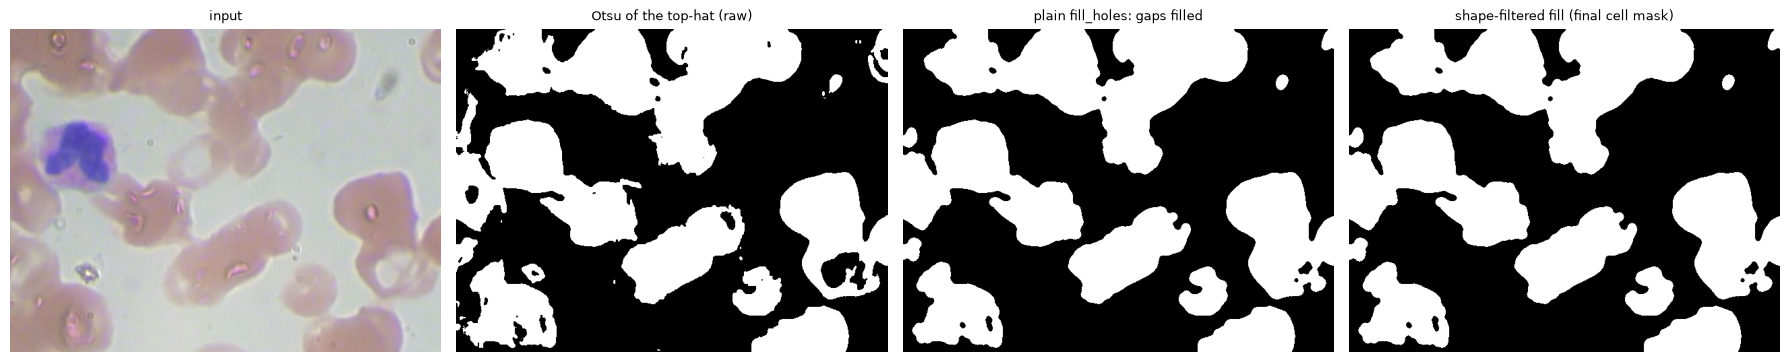

In [2]:
steps = a.seg.steps
plain = clean_mask(
    steps["cells_union_purple"], r, with_overrides(cfg, {("segmentation", "hole_fill"): "plain"})
)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
show(ax[0], img, "input")
show(ax[1], steps["cells_otsu"], "Otsu of the top-hat (raw)", cmap="gray")
show(ax[2], plain, "plain fill_holes: gaps filled", cmap="gray")
show(ax[3], a.seg.cell_mask, "shape-filtered fill (final cell mask)", cmap="gray")
diff = plain & ~a.seg.cell_mask
ax[2].contour(diff, levels=[0.5], colors="red", linewidths=1)
fig.tight_layout()
fig.savefig(FIG / "hole_fill_plain_vs_shape.png", dpi=110)
print(f"plain fill adds {diff.sum() / (np.pi * r**2):.2f} pi r^2 of background (red)")

## 2. WBC branch: nucleus, gradient watershed, N/C ratio

* **Nucleus**: large components of the purple mask; a closing of 0.15 r groups the lobes of a
  segmented nucleus (neutrophil) into one object.
* **Whole cell**: marker-controlled watershed of the morphological gradient (dilation − erosion of
  the green and purple channels). Markers: the nucleus (grown 3 px past its own edge ridge), a
  background marker (far from the nucleus, or clearly background in the top-hat) and the centres of
  the touching RBCs, so that an RBC is not absorbed into the WBC.
* **N/C** = nucleus area / cytoplasm area.

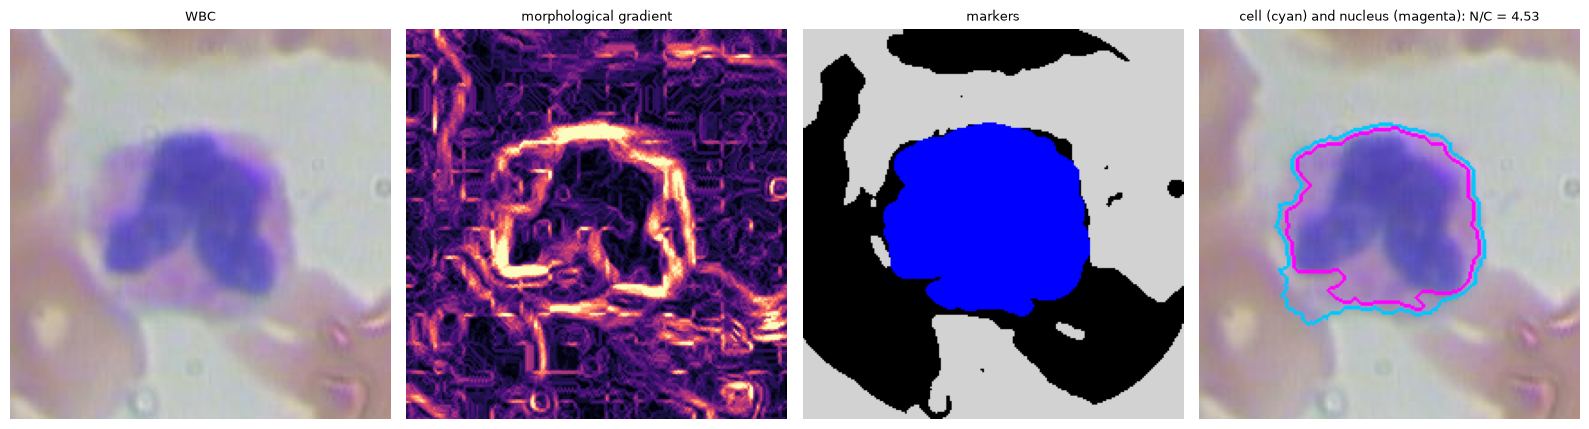

In [3]:
k = int(np.bincount(a.wbc.nuclei.ravel())[1:].argmax()) + 1 if a.wbc.nuclei.max() else 0
if k:
    sl = ndi.find_objects((a.wbc.cells == k).astype(np.int32))[0]
    pad = int(0.8 * r)
    sl = tuple(slice(max(0, s.start - pad), s.stop + pad) for s in sl)
    nucleus, cell = a.wbc.nuclei[sl] == k, a.wbc.cells[sl] == k
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    show(ax[0], img[sl], "WBC")
    show(ax[1], a.wbc.gradient[sl], "morphological gradient", cmap="magma")
    markers = a.wbc.markers[sl]
    show(ax[2], color.label2rgb(markers, bg_label=0, colors=["blue", "lightgray", "red"] * 10), "markers")
    over = img[sl].copy()
    over[mask_contours(cell, 2)] = (0, 200, 255)
    over[mask_contours(nucleus, 2)] = (255, 0, 255)
    nc = nucleus.sum() / max(cell.sum() - nucleus.sum(), 1)
    show(ax[3], over, f"cell (cyan) and nucleus (magenta): N/C = {nc:.2f}")
    fig.tight_layout()
    fig.savefig(FIG / "wbc_gradient_watershed.png", dpi=110)

## 3. Platelets: grouping and enclosure

Purple components of 0.005 to 0.3 π r² outside the WBC are candidates. Many are stain specks or
bluish pale centres **inside** an RBC. A thin ring (0.08 r to 0.18 r) around each candidate is
measured: when more than half of it lies in non-purple cell pixels, the speck is enclosed in a
cell and rejected. On the BCCD train set this keeps 179 / 187 labelled platelets and removes
80 % of the other candidates.

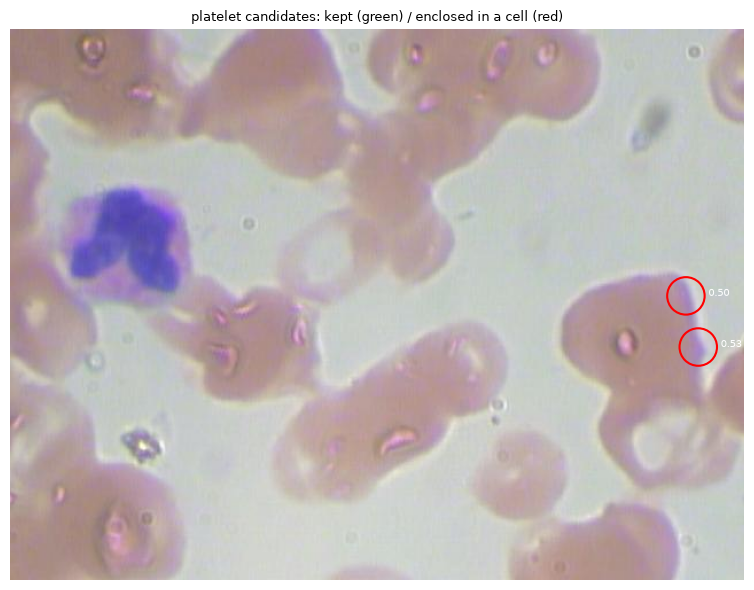

In [4]:
from bloodcells.platelets import enclosure, group_components  # noqa: E402
from bloodcells.segmentation import disk_radius  # noqa: E402

cand = a.seg.purple_mask & (a.wbc.cells == 0)
groups = group_components(cand, disk_radius(cfg["platelets"]["group_r"], r))
enc = enclosure(groups, a.seg.cell_mask & ~a.seg.purple_mask, 0.08 * r, 0.18 * r)
fig, ax = plt.subplots(figsize=(8, 6))
show(ax, img, "platelet candidates: kept (green) / enclosed in a cell (red)")
for p in measure.regionprops(groups):
    if p.area > cfg["platelets"]["area_max"] * np.pi * r**2:
        continue
    y, x = p.centroid
    kept = (a.platelets[groups == p.label] > 0).any()
    ax.add_patch(plt.Circle((x, y), 0.25 * r, fill=False, ec="lime" if kept else "red", lw=1.5))
    ax.text(x + 0.3 * r, y, f"{enc[p.label]:.2f}", color="w", fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "platelet_enclosure.png", dpi=110)

## 4. Splitting touching RBCs

The RBC mask is the cell mask minus the WBCs and the (dilated) platelets. Its **distance transform**
peaks at the cell centres and drops at the necks between touching cells. The **h-maxima** keep a
peak only if it rises at least `h` above the neck joining it to a higher peak; the **watershed** of
the inverted distance, flooded from these markers inside the mask, cuts along the necks.
Components without a marker are kept as their own label.

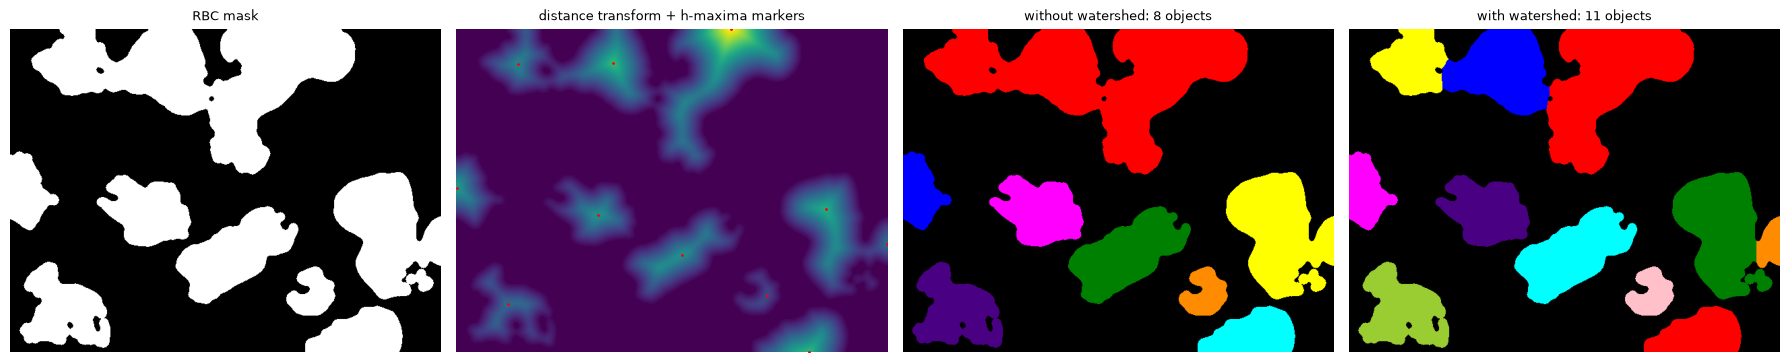

In [5]:
sep = a.sep
no_ws = measure.label(a.rbc_mask)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
show(ax[0], a.rbc_mask, "RBC mask", cmap="gray")
show(ax[1], sep.distance, "distance transform + h-maxima markers", cmap="viridis")
yy, xx = np.nonzero(sep.markers)
ax[1].plot(xx, yy, ".", color="red", ms=2)
show(ax[2], color.label2rgb(no_ws, bg_label=0), f"without watershed: {no_ws.max()} objects")
show(ax[3], color.label2rgb(sep.labels, bg_label=0), f"with watershed: {sep.labels.max()} objects")
fig.tight_layout()
fig.savefig(FIG / "watershed_before_after.png", dpi=110)

### Effect of `h` (over- vs under-segmentation)

Too small: each bump of the distance (notches of C-shaped RBCs) becomes a marker, cells are cut in
pieces. Too large: two touching cells share one marker and stay merged. `h` is chosen on train /
val by detection recall and the predicted / labelled count ratio
(`make eval-detection`, `run_evaluation.py --ablation`, sweeps figure).

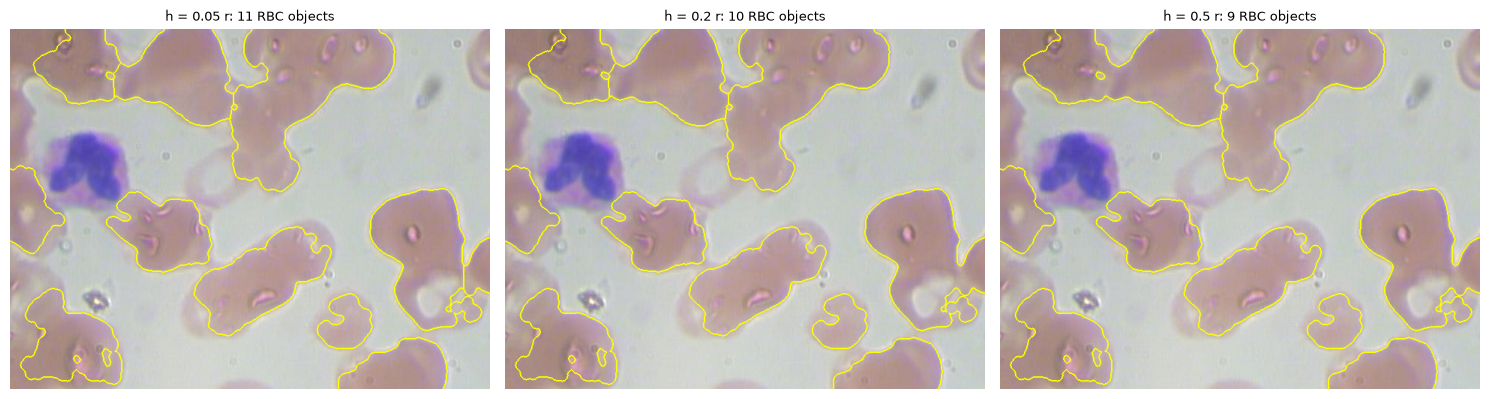

In [6]:
hs = [0.05, 0.2, 0.5]
fig, ax = plt.subplots(1, len(hs), figsize=(15, 4.2))
for axi, h in zip(ax, hs):
    ah = analyze(img, with_overrides(cfg, {("separation", "h"): h}), r=r)
    over = img.copy()
    over[label_contours(ah.sep.labels)] = (255, 255, 0)
    show(axi, over, f"h = {h} r: {ah.sep.labels.max()} RBC objects")
fig.tight_layout()
fig.savefig(FIG / "h_effect.png", dpi=110)

## 5. Contours: label map vs binary mask

The contour of the binary mask (mask minus its erosion) ignores the watershed lines: two split
cells look like one. The **morphological gradient of the label map**,
`dilation(labels) != erosion(labels)`, is also non-zero where two labels meet.

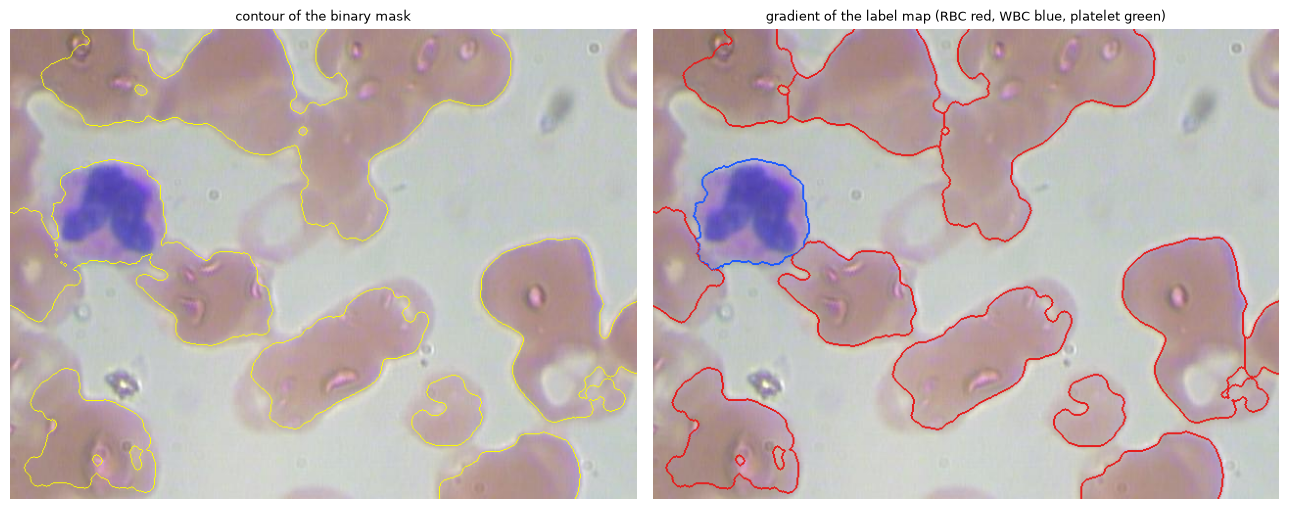

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
m = img.copy()
m[mask_contours(a.labels > 0, 1)] = (255, 255, 0)
show(ax[0], m, "contour of the binary mask")
show(
    ax[1],
    class_overlay(img, a.labels, a.branch),
    "gradient of the label map (RBC red, WBC blue, platelet green)",
)
fig.tight_layout()
fig.savefig(FIG / "contours_mask_vs_labels.png", dpi=110)

## 6. Bonus: SKIZ and ultimate erosion on the largest clump

The **ultimate erosion** (regional maxima of the distance) leaves one piece per convex cell; its
number estimates the cells in a clump. The **SKIZ** of these pieces inside the clump (geodesic
zones of influence) is the morphological skeleton the watershed is built on.

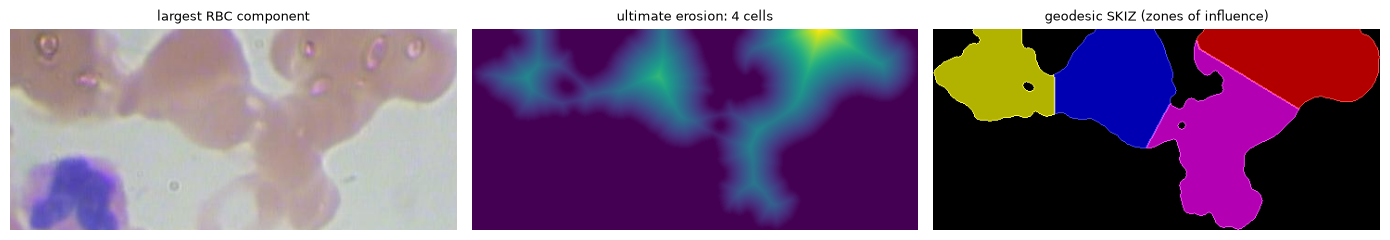

In [8]:
comp = measure.label(a.rbc_mask)
big = int(np.bincount(comp.ravel())[1:].argmax()) + 1
sl = ndi.find_objects((comp == big).astype(np.int32))[0]
clump = comp[sl] == big
ue = measure.label(morphology.h_maxima(ndi.distance_transform_edt(clump), 0.05 * r) > 0, connectivity=2)
zones, lines = skiz(ue, mask=clump)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
show(ax[0], img[sl], "largest RBC component")
show(
    ax[1],
    ndi.distance_transform_edt(clump),
    f"ultimate erosion: {ultimate_erosion_count(clump, r)} cells",
    cmap="viridis",
)
show(
    ax[2],
    color.label2rgb(zones, bg_label=0) * 0.7 + 0.3 * lines[..., None],
    "geodesic SKIZ (zones of influence)",
)
fig.tight_layout()
fig.savefig(FIG / "skiz_ultimate_erosion.png", dpi=110)

## 7. Final result on a few train / val images

Classes come from the saved classifier when `models/classifier.joblib` exists, otherwise from the
branch. Clumps are counted by area / median RBC area.

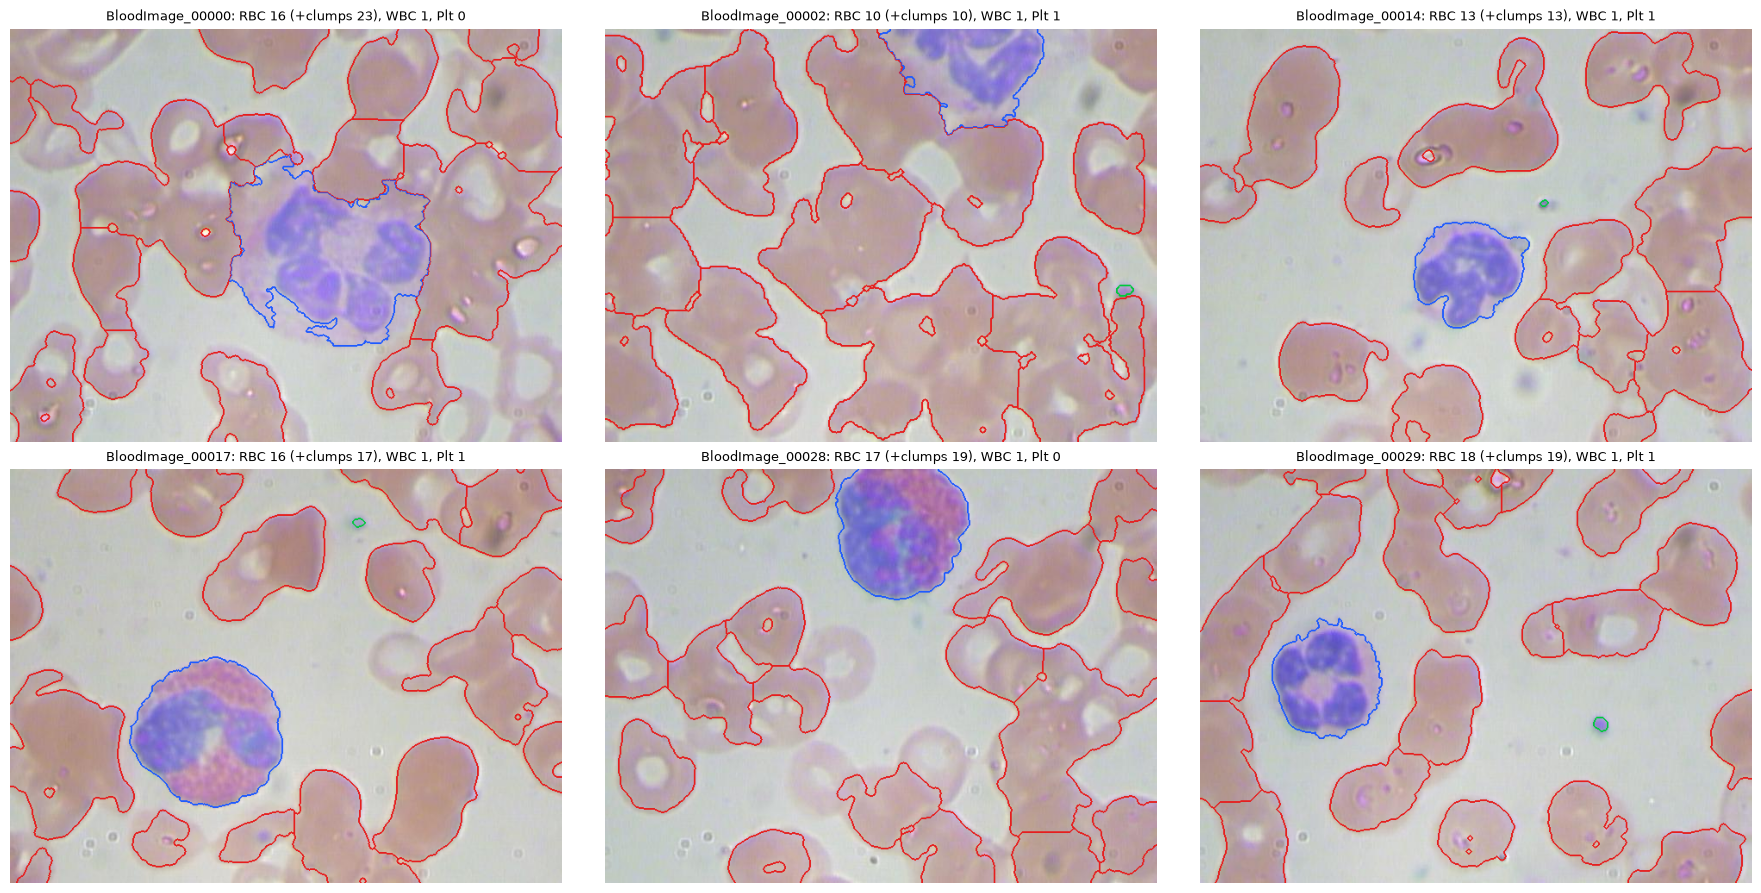

In [9]:
from bloodcells.classifier import load_model  # noqa: E402
from bloodcells.config import PROJECT_ROOT  # noqa: E402

model = load_model(PROJECT_ROOT / cfg["classifier"]["model_file"])
ids = data.ids("val")[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for axi, i in zip(axes.ravel(), ids):
    res = run(load_image(data.images.loc[i, "image_path"]), cfg, model=model)
    c = res.counts
    show(
        axi,
        res.overlay(),
        f"{i}: RBC {c['RBC']} (+clumps {c['RBC_with_clumps']}), WBC {c['WBC']}, Plt {c['Platelet']}",
    )
fig.tight_layout()
fig.savefig(FIG / "final_overlays.png", dpi=90)